# Jacobik test suite & debugging hub

A single notebook to run a curated set of chemically-meaningful test complexes,
check the results against independent chemical-realism criteria (not just the
optimized score), and visualize everything needed to debug a regression:
score breakdown by term, IK convergence trace, D&ndash;M&ndash;D angle
distribution, 3D structure, ensemble diversity, and stats-fallback depth.

**How to use this notebook**

- Run top to bottom once to get a pass/fail dashboard across all registered
  cases (`SUMMARY_DF` near the bottom of the batch-run section).
- For anything that fails or looks off, jump to **Debugging playground**
  at the end, set `CASE_NAME` to the case in question, and rerun with
  `debug=True` for full solver diagnostics plus every plot in one place.
- Add new cases by appending to `TEST_CASES` &mdash; nothing else needs to
  change; the batch runner and all checks are generic over the registry.

**Note on `data/notebooks/benchmark_workbench.ipynb`**: that notebook
references `jacobik.vis.benchmark_workbench` and a `benchmarks/` directory
(cases.json, run_case.py) that are **not present in this repository** and
are not recoverable from git history on `main` or `origin/dev` &mdash;
apparently uncommitted work from an earlier session that's now gone. The
`data/out/*_control.json` / `*_baseline.json` files are leftover output
from that lost system. This notebook is a fresh, self-contained
replacement built only against the current, working public API.


## 0. Setup

In [1]:
from __future__ import annotations

import math
import sys,os
import time
from pathlib import Path

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

def _find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists() and (candidate / "src" / "jacobik").exists():
            return candidate
    raise RuntimeError(
        "Could not find the Jacobik project root (looked for pyproject.toml "
        "+ src/jacobik above the notebook's directory). Open this notebook "
        "from inside the project tree."
    )

PROJECT_ROOT = _find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from jacobik import ComplexBuilder, LigandInput
from jacobik.ik.ik_solver import IKSolverConfig
from jacobik.stats.stats import StatsLookup, load_db
from jacobik.topology.coord_geom import classify as classify_geometry
from jacobik.topology.graph import build_heavy_ligand_graph
import networkx as nx

CONSTRAINTS_DB = PROJECT_ROOT / "src" / "jacobik" / "constraints.json"
DEVICE = torch.device("cpu")

print(f"Project root   : {PROJECT_ROOT}")
print(f"Constraints DB : {CONSTRAINTS_DB}  (exists={CONSTRAINTS_DB.exists()})")


Project root   : C:\Users\alanc\sus folder\CCCSEF\Jacobik v3
Constraints DB : C:\Users\alanc\sus folder\CCCSEF\Jacobik v3\src\jacobik\constraints.json  (exists=True)


### Environment check

Package versions matter for exact reproducibility of a given seed (see
`script_notebooks/reproduce_edta_results.py`). Not a hard requirement to
match, but worth recording alongside any result you're comparing across
sessions or machines.


In [2]:
import numpy as _np
import rdkit as _rdkit

print(f"python : {sys.version.split()[0]}")
print(f"torch  : {torch.__version__}")
print(f"numpy  : {_np.__version__}")
print(f"rdkit  : {_rdkit.__version__}")

# Load the stats DB once; every case below reuses this instance (avoids
# re-parsing a multi-MB JSON per case in the batch run).
STATS = StatsLookup(load_db(CONSTRAINTS_DB))
print("\nStats DB loaded.")


python : 3.10.20
torch  : 2.11.0+cpu
numpy  : 2.2.6
rdkit  : 2025.09.6

Stats DB loaded.


## 1. Test case registry

Each case is chosen to stress a specific, previously-diagnosed failure mode
rather than being an arbitrary example:

| case | tests |
|---|---|
| `pt_cl4_square_planar` | planarity enforcement (the "square planar becomes a tetrahedron corner" failure) |
| `zn_cl4_tetrahedral` | same CN=4 donor set size as PtCl4 but a *different* target shape &mdash; confirms the solver isn't just always relaxing to one attractor |
| `fe_co5_trig_bipyr` | axial/equatorial distinction under CN=5 |
| `co_nh3_6_octahedral` | simplest possible closed-shell octahedral case; a monodentate baseline canary, and the simplest case that exercises the spin/multiplicity fix directly |
| `co_en3_octahedral` | tris-chelate sterics, N&ndash;M bond-length uniformity, bite angle |
| `co_edta_octahedral` | the flagship hexadentate stress case: initialization diversity, dangling-arm risk |
| `fe_h2o_6_highspin` | deliberately data-sparse (high-spin, multiplicity=5) &mdash; demonstrates honest fallback rather than silently wrong precision |

`spin` is **multiplicity (2S+1)**, matching `ComplexBuilder`'s documented
convention &mdash; 1 for any diamagnetic/closed-shell complex.


In [3]:
TEST_CASES = [
    dict(
        name="pt_cl4_square_planar",
        metal="Pt", geometry="square_plan", charge=-2, spin=1,
        smiles="[Cl-]", donors=[[0]], n_ligands=4,
        note="Classic textbook square-planar d8 Pt(II). Expect a flat CN4 "
             "shell; watch for tetrahedral-like drift (shape check below).",
    ),
    dict(
        name="zn_cl4_tetrahedral",
        metal="Zn", geometry="tetrahedral", charge=-2, spin=1,
        smiles="[Cl-]", donors=[[0]], n_ligands=4,
        note="Same donor set size/type as PtCl4 but the opposite CN4 shape "
             "-- contrast case.",
    ),
    dict(
        name="fe_co5_trig_bipyr",
        metal="Fe", geometry="trig_bipyr", charge=0, spin=1,
        smiles="[C-]#[O+]", donors=[[0]], n_ligands=5,
        note="Fe(CO)5, D3h, diamagnetic 18e Fe(0). CO binds through carbon "
             "(donor index 0).",
    ),
    dict(
        name="co_nh3_6_octahedral",
        metal="Co", geometry="octahedral", charge=3, spin=1,
        smiles="N", donors=[[0]], n_ligands=6,
        note="[Co(NH3)6]3+, low-spin Co(III), monodentate -- simplest "
             "possible octahedral baseline.",
    ),
    dict(
        name="co_en3_octahedral",
        metal="Co", geometry="octahedral", charge=3, spin=1,
        smiles="NCCN", donors=[[0], [3]], n_ligands=3,
        note="[Co(en)3]3+, D3 propeller, three bidentate 5-membered "
             "chelate rings. Bite angle should cluster ~75-90 deg.",
    ),
    dict(
        name="co_edta_octahedral",
        metal="Co", geometry="octahedral", charge=-1, spin=1,
        smiles="[O-]C(=O)CN(CCN(CC(=O)[O-])CC(=O)[O-])CC(=O)[O-]",
        donors=[[0], [4], [7], [11], [15], [19]], n_ligands=1,
        note="Co-EDTA, hexadentate. Historically prone to a dangling arm; "
             "same case as script_notebooks/reproduce_edta_results.py.",
        solve_kwargs=dict(beam_width=32, n_ik_steps=200),
    ),
    dict(
        name="fe_h2o_6_highspin",
        metal="Fe", geometry="octahedral", charge=2, spin=5,
        smiles="O", donors=[[0]], n_ligands=6,
        note="[Fe(H2O)6]2+, HIGH-SPIN (multiplicity=5). tmQM is almost "
             "entirely closed-shell, so this should honestly fall back to "
             "a coarser Q1 entry rather than finding an exact spin=5 key "
             "-- expected behaviour, not a bug. See the stats-introspection "
             "section.",
    ),
    dict(
        name="la_polyester_octahedral",
        metal="La", geometry="octahedral", charge=3, spin=1,
        smiles="C(=O)(OCC(=O)OC(C)C(C)[O-])CC(=O)OCC(C)OC(=O)C[O-]",
        donors=[[2], [6], [11], [15], [19], [23]], n_ligands=1,
        note="La(III) wrapped by one long, floppy neutral polyester/polyol "
             "ligand -- first lanthanide case and first CN7 case in this "
             "suite (La3+ is 4f0, closed-shell, so spin=1 is unambiguous; "
             "swap metal='Gd' + spin=8 or metal='Eu' + spin=7 to try an "
             "open-shell lanthanide once this baseline is solid). Donors "
             "are the ketone O (idx0), both terminal alcohols (idx3, "
             "idx25), and the four ester CARBONYL O's (idx7, idx12, "
             "idx15, idx19). The corresponding SMILES atom indices "
             "4, 9, and 24 are carbons (two of them terminal methyls) "
             "and can't coordinate at all -- corrected here to real "
             "donor oxygens, keeping idx3/15/19 which were already "
             "valid. The four ester ALKOXY oxygens (idx5, idx10, idx16, "
             "idx20) are deliberately excluded too: their lone pairs are "
             "conjugated into their own carbonyl, making them much "
             "weaker donors than the C=O sitting right next to them, so "
             "a hard, high-CN ion like La3+ should preferentially bind "
             "the carbonyls instead. idx12/idx15 flank a central CH2 "
             "(a malonate-diester unit) and form a favourable 6-membered "
             "chelate ring; the rest of the backbone gives looser "
             "6-7-membered rings, typical of a big, flexible wraparound "
             "ionophore rather than a tight, pre-organised chelator like "
             "EDTA. This ligand has no topological donor symmetry (unlike "
             "EDTA's matched pairs), so it exercises coverage -- a new "
             "metal family, a new CN/geometry (pent_bipyr, CN7, not yet "
             "tried elsewhere in this suite), heterogeneous donor "
             "subclasses (ketone O + ester O + alcohol O all at once), "
             "and a much longer torsion chain -- rather than the "
             "symmetric-tie / branch-bend machinery fixed above.",
    ),
]

CASES_BY_NAME = {c["name"]: c for c in TEST_CASES}
print(f"{len(TEST_CASES)} registered cases:")
for c in TEST_CASES:
    print(f"  - {c['name']}")


8 registered cases:
  - pt_cl4_square_planar
  - zn_cl4_tetrahedral
  - fe_co5_trig_bipyr
  - co_nh3_6_octahedral
  - co_en3_octahedral
  - co_edta_octahedral
  - fe_h2o_6_highspin
  - la_polyester_octahedral


## 2. Run harness

`EnsembleResult` already carries everything needed for diagnostics directly
(`solve_trace`, the shared `scorer` instance) &mdash; no need to rebuild a
`Scorer`/`GeometryExtractor` by hand or monkeypatch anything.


In [4]:
DEFAULT_SOLVE_KWARGS = dict(
    beam_width=16,
    n_ik_steps=200,
    lr=0.1,
    n_coord_samples=8,
    seed=42,
)


def build_case_complex(case: dict) -> ComplexBuilder:
    ligands = [LigandInput(case["smiles"], donors=case["donors"]) for _ in range(case["n_ligands"])]
    return ComplexBuilder(
        metal=case["metal"],
        geometry=case["geometry"],
        charge=case["charge"],
        spin=case["spin"],
        ligands=ligands,
    )


def run_case(case: dict, stats=STATS, debug: bool = False, **overrides):
    """
    Build + solve one registered case. Returns (EnsembleResult, elapsed_seconds).

    Prints a cheap sanity check of the resolved donor subclasses BEFORE the
    (expensive) solve -- catches a wrong SMILES/donor-index pair immediately
    instead of after a multi-second solve.
    """
    builder = build_case_complex(case)
    kwargs = {**DEFAULT_SOLVE_KWARGS, **case.get("solve_kwargs", {}), **overrides}

    t0 = time.perf_counter()
    result = builder.solve(constraints_db=CONSTRAINTS_DB, stats=stats, debug=debug, **kwargs)
    elapsed = time.perf_counter() - t0

    if result.best is not None:
        mol0 = result.best.complex
        subclasses = sorted({lbl.subclass for lbl in mol0.donor_labels.values()})
        print(
            f"[{case['name']}] solved in {elapsed:.1f}s -- "
            f"{len(result.converged)}/{len(result.conformers)} converged -- "
            f"best score={result.best.score:.4f} -- donor subclasses={subclasses}"
        )
    return result, elapsed


## 3. Chemical-realism checks

Independent of the optimized score, per Phase 2 of the project's own
robustness roadmap ("benchmark success is reported independently of the
optimization score"). Each check returns `{"pass": bool, ...details}`.


In [5]:
def donor_metal_distances(mol) -> tuple[list[int], np.ndarray]:
    donor_idxs = sorted(mol.donor_labels.keys())
    metal_pos = np.asarray(mol.get_atom(mol.metal_idx).position, dtype=float)
    dists = np.array(
        [np.linalg.norm(np.asarray(mol.get_atom(d).position, dtype=float) - metal_pos) for d in donor_idxs]
    )
    return donor_idxs, dists


def dmd_angles_deg(mol) -> tuple[list[int], np.ndarray, list[tuple[int, int]]]:
    donor_idxs, _ = donor_metal_distances(mol)
    metal_pos = np.asarray(mol.get_atom(mol.metal_idx).position, dtype=float)
    vecs = np.array([np.asarray(mol.get_atom(d).position, dtype=float) - metal_pos for d in donor_idxs])
    vecs = vecs / np.linalg.norm(vecs, axis=1, keepdims=True)
    n = len(vecs)
    angles, pairs = [], []
    for i in range(n):
        for j in range(i + 1, n):
            cos_t = float(np.clip(np.dot(vecs[i], vecs[j]), -1.0, 1.0))
            angles.append(math.degrees(math.acos(cos_t)))
            pairs.append((donor_idxs[i], donor_idxs[j]))
    return donor_idxs, np.array(angles), pairs


def find_chelate_pairs(mol, max_hops: int = 4) -> list[tuple[int, int, int]]:
    """Donor pairs within max_hops on the heavy-atom ligand graph (same
    logic used for the chelate bite-angle repair in ik/targets.py)."""
    G = build_heavy_ligand_graph(mol.atoms, mol.bonds, mol.metal_idx)
    donor_idxs = sorted(mol.donor_labels.keys())
    pairs = []
    for i, di in enumerate(donor_idxs):
        if not G.has_node(di):
            continue
        for dj in donor_idxs[i + 1:]:
            if not G.has_node(dj):
                continue
            try:
                hops = nx.shortest_path_length(G, di, dj)
            except nx.NetworkXNoPath:
                continue
            if hops <= max_hops:
                pairs.append((di, dj, hops))
    return pairs


def check_shape_match(mol, expected_geometry: str) -> dict:
    actual = classify_geometry(mol)
    return {
        "pass": actual == expected_geometry,
        "expected": expected_geometry,
        "actual": actual,
        "message": "OK" if actual == expected_geometry else f"classified as {actual!r}, expected {expected_geometry!r}",
    }


def check_bond_length_spread(mol, max_spread_A: float = 0.35) -> dict:
    donor_idxs, dists = donor_metal_distances(mol)
    spread = float(dists.max() - dists.min()) if len(dists) else 0.0
    return {
        "pass": spread <= max_spread_A,
        "spread_A": spread,
        "min_A": float(dists.min()) if len(dists) else None,
        "max_A": float(dists.max()) if len(dists) else None,
        "message": "OK" if spread <= max_spread_A else f"M-D distances span {spread:.2f} A (max allowed {max_spread_A})",
    }


def check_dangling_arm(mol, threshold_A: float = 0.6) -> dict:
    donor_idxs, dists = donor_metal_distances(mol)
    if len(dists) == 0:
        return {"pass": True, "message": "no donors"}
    med = float(np.median(dists))
    excess = dists - med
    outlier_mask = excess > threshold_A
    outliers = [donor_idxs[i] for i in np.where(outlier_mask)[0]]
    return {
        "pass": not outlier_mask.any(),
        "median_A": med,
        "max_excess_A": float(excess.max()),
        "outlier_donors": outliers,
        "message": "OK" if not outliers else f"donor atom(s) {outliers} sit {float(excess.max()):.2f} A beyond median M-D distance",
    }


def check_metal_clashes(mol, min_A: float = 1.8) -> dict:
    donor_set = set(mol.donor_labels.keys())
    metal_pos = np.asarray(mol.get_atom(mol.metal_idx).position, dtype=float)
    dists = [
        float(np.linalg.norm(np.asarray(a.position, dtype=float) - metal_pos))
        for a in mol.atoms
        if a.idx != mol.metal_idx and a.idx not in donor_set and a.symbol != "H"
    ]
    closest = min(dists) if dists else float("inf")
    return {
        "pass": closest >= min_A,
        "closest_non_donor_A": closest,
        "message": "OK" if closest >= min_A else f"non-donor heavy atom {closest:.2f} A from metal (< {min_A})",
    }


def check_chelate_bite_angles(mol, lo: float = 60.0, hi: float = 115.0) -> dict:
    pairs = find_chelate_pairs(mol)
    if not pairs:
        return {"pass": True, "n_chelate_pairs": 0, "details": [], "message": "no chelate pairs"}
    metal_pos = np.asarray(mol.get_atom(mol.metal_idx).position, dtype=float)
    details = []
    for di, dj, hops in pairs:
        vi = np.asarray(mol.get_atom(di).position, dtype=float) - metal_pos
        vj = np.asarray(mol.get_atom(dj).position, dtype=float) - metal_pos
        cos_t = float(np.clip(np.dot(vi, vj) / (np.linalg.norm(vi) * np.linalg.norm(vj)), -1.0, 1.0))
        angle = math.degrees(math.acos(cos_t))
        details.append({"donors": (di, dj), "hops": hops, "bite_deg": angle, "pass": lo <= angle <= hi})
    passed = all(d["pass"] for d in details)
    worst = min(details, key=lambda d: min(abs(d["bite_deg"] - lo), abs(d["bite_deg"] - hi)) if not d["pass"] else 1e9)
    return {
        "pass": passed,
        "n_chelate_pairs": len(details),
        "details": details,
        "message": "OK" if passed else f"donors {worst['donors']} bite angle {worst['bite_deg']:.1f} deg outside [{lo},{hi}]",
    }


def pairwise_rmsd_matrix(conformers) -> np.ndarray:
    """Heavy-atom, Kabsch-aligned pairwise RMSD across kept conformers
    (same construction engine.py's own debug=True path uses)."""
    heavy_idx = [i for i, a in enumerate(conformers[0].complex.atoms) if a.symbol != "H" and a.idx != conformers[0].complex.metal_idx]
    coords = [np.array([c.complex.atoms[i].position for i in heavy_idx]) for c in conformers]
    n = len(conformers)
    M = np.zeros((n, n))
    for i in range(n):
        for j in range(i + 1, n):
            Pc = coords[i] - coords[i].mean(axis=0)
            Qc = coords[j] - coords[j].mean(axis=0)
            H = Pc.T @ Qc
            U, _, Vt = np.linalg.svd(H)
            d = np.sign(np.linalg.det(Vt.T @ U.T))
            S = np.eye(3); S[-1, -1] = d
            R = Vt.T @ S @ U.T
            rmsd = float(np.sqrt(((Pc @ R.T - Qc) ** 2).sum(axis=-1).mean()))
            M[i, j] = M[j, i] = rmsd
    return M


def check_ensemble_diversity(conformers, collapsed_rmsd_A: float = 0.05) -> dict:
    if len(conformers) < 2:
        return {"pass": True, "message": "single conformer, diversity N/A"}
    M = pairwise_rmsd_matrix(conformers)
    iu = np.triu_indices_from(M, k=1)
    mean_offdiag = float(M[iu].mean())
    return {
        "pass": mean_offdiag > collapsed_rmsd_A,
        "mean_pairwise_rmsd_A": mean_offdiag,
        "message": "OK" if mean_offdiag > collapsed_rmsd_A else f"ensemble looks collapsed (mean pairwise RMSD {mean_offdiag:.3f} A)",
    }


def run_all_checks(result, case: dict) -> dict:
    mol = result.best.complex
    return {
        "shape": check_shape_match(mol, case["geometry"]),
        "bond_spread": check_bond_length_spread(mol),
        "dangling_arm": check_dangling_arm(mol),
        "clashes": check_metal_clashes(mol),
        "chelate_bite": check_chelate_bite_angles(mol),
        "diversity": check_ensemble_diversity(result.conformers),
    }


## 4. Batch run &mdash; the dashboard

Runs every registered case once and tabulates score, convergence, and every
realism check into one DataFrame. This is the first thing to check after any
solver/scoring change.


In [6]:
RESULTS: dict[str, object] = {}   # case name -> EnsembleResult
ELAPSED: dict[str, float] = {}
CHECKS: dict[str, dict] = {}

rows = []
for case in TEST_CASES:
    try:
        result, elapsed = run_case(case)
    except Exception as exc:
        rows.append({"case": case["name"], "error": str(exc)})
        print(f"[{case['name']}] FAILED TO SOLVE: {exc}")
        continue

    RESULTS[case["name"]] = result
    ELAPSED[case["name"]] = elapsed
    checks = run_all_checks(result, case)
    CHECKS[case["name"]] = checks

    row = {
        "case": case["name"],
        "n_converged": len(result.converged),
        "n_total": len(result.conformers),
        "best_score": result.best.score if result.best else float("nan"),
        "elapsed_s": round(elapsed, 1),
    }
    for check_name, check_result in checks.items():
        row[check_name] = check_result["pass"]
    rows.append(row)

SUMMARY_DF = pd.DataFrame(rows).set_index("case")
SUMMARY_DF


[pt_cl4_square_planar] solved in 4.7s -- 16/16 converged -- best score=1.9888 -- donor subclasses=['Hal_Cl']
[zn_cl4_tetrahedral] solved in 5.2s -- 16/16 converged -- best score=0.3608 -- donor subclasses=['Hal_Cl']


[20:14:53] Explicit valence for atom # 1 O, 3, is greater than permitted
[20:14:53] Explicit valence for atom # 1 O, 3, is greater than permitted
[20:14:53] Explicit valence for atom # 1 O, 3, is greater than permitted
[20:14:53] Explicit valence for atom # 1 O, 3, is greater than permitted
[20:14:53] Explicit valence for atom # 1 O, 3, is greater than permitted


[fe_co5_trig_bipyr] solved in 10.0s -- 16/16 converged -- best score=3.3194 -- donor subclasses=['C_donor']
[co_nh3_6_octahedral] solved in 13.6s -- 16/16 converged -- best score=-0.2965 -- donor subclasses=['N_amine']
[co_en3_octahedral] solved in 19.7s -- 15/16 converged -- best score=-0.9617 -- donor subclasses=['N_amine']
[co_edta_octahedral] solved in 29.3s -- 10/32 converged -- best score=-5.2741 -- donor subclasses=['N_amine', 'O_carboxylate']
[fe_h2o_6_highspin] solved in 14.1s -- 16/16 converged -- best score=-5.1744 -- donor subclasses=['O_water']
[la_polyester_octahedral] solved in 22.9s -- 0/16 converged -- best score=-10.4280 -- donor subclasses=['O_alkoxide', 'O_ether']


,n_converged,n_total,best_score,elapsed_s,shape,bond_spread,dangling_arm,clashes,chelate_bite,diversity
case,,,,,,,,,,
pt_cl4_square_planar,16,16,1.988797,4.7,True,True,True,True,True,False
zn_cl4_tetrahedral,16,16,0.360787,5.2,True,True,True,True,True,True
fe_co5_trig_bipyr,16,16,3.319432,10.0,True,True,True,True,True,True
co_nh3_6_octahedral,16,16,-0.296544,13.6,True,True,True,True,True,False
co_en3_octahedral,15,16,-0.961711,19.7,True,True,True,True,True,True
co_edta_octahedral,10,32,-5.274068,29.3,True,True,True,True,True,True
fe_h2o_6_highspin,16,16,-5.174377,14.1,True,True,True,True,True,False
la_polyester_octahedral,0,16,-10.427959,22.9,True,False,True,True,True,True


In [7]:
_check_cols = [c for c in SUMMARY_DF.columns if c not in ("n_converged", "n_total", "best_score", "elapsed_s", "error")]

def _style_bool(v):
    if isinstance(v, bool):
        return "background-color: #d4edda" if v else "background-color: #f8d7da; font-weight: bold"
    return ""

SUMMARY_DF.style.applymap(_style_bool, subset=_check_cols)


C:\Users\alanc\AppData\Local\Temp\ipykernel_32144\1370144875.py:8: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  SUMMARY_DF.style.applymap(_style_bool, subset=_check_cols)


,n_converged,n_total,best_score,elapsed_s,shape,bond_spread,dangling_arm,clashes,chelate_bite,diversity
case,,,,,,,,,,
pt_cl4_square_planar,16,16,1.988797,4.700000,True,True,True,True,True,False
zn_cl4_tetrahedral,16,16,0.360787,5.200000,True,True,True,True,True,True
fe_co5_trig_bipyr,16,16,3.319432,10.000000,True,True,True,True,True,True
co_nh3_6_octahedral,16,16,-0.296544,13.600000,True,True,True,True,True,False
co_en3_octahedral,15,16,-0.961711,19.700000,True,True,True,True,True,True
co_edta_octahedral,10,32,-5.274068,29.300000,True,True,True,True,True,True
fe_h2o_6_highspin,16,16,-5.174377,14.100000,True,True,True,True,True,False
la_polyester_octahedral,0,16,-10.427959,22.900000,True,False,True,True,True,True


## 5. Score breakdown (Q1&ndash;Q6)

Which term the score is actually coming from for the best conformer of a
given case &mdash; `result.scorer` is the shared `Scorer` built on the full
complex; feed it any conformer's atom positions.


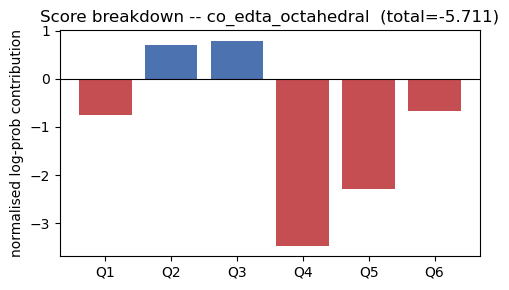

In [8]:
def score_breakdown_for(result, conformer=None) -> dict[str, float]:
    conformer = conformer or result.best
    X = torch.tensor(
        np.stack([a.position for a in conformer.complex.atoms]), dtype=torch.float32
    ).unsqueeze(0)
    _, breakdown = result.scorer.score(X)
    return {k: float(v.item()) for k, v in breakdown.items()}


def plot_score_breakdown(result, title=""):
    bd = score_breakdown_for(result)
    fig, ax = plt.subplots(figsize=(5, 3))
    keys = list(bd.keys())
    vals = [bd[k] for k in keys]
    colors = ["#4c72b0" if v >= 0 else "#c44e52" for v in vals]
    ax.bar(keys, vals, color=colors)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylabel("normalised log-prob contribution")
    ax.set_title(f"Score breakdown -- {title}  (total={sum(vals):.3f})")
    plt.tight_layout()
    plt.show()
    return bd


# Example: EDTA, the flagship stress case
plot_score_breakdown(RESULTS["co_edta_octahedral"], "co_edta_octahedral");


## 6. IK convergence trace

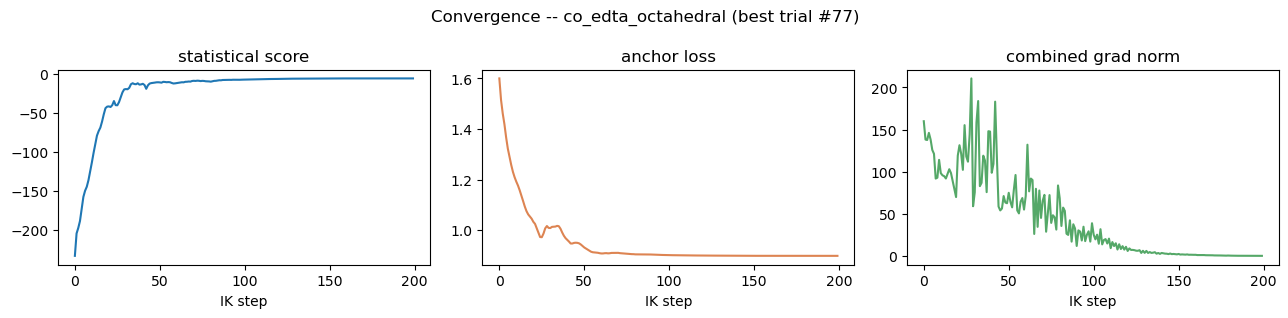

In [9]:
def plot_convergence(result, case_name=""):
    trace = result.solve_trace
    if not trace:
        print("No solve_trace on this result.")
        return
    b = result.best.trial_idx  # column into (T, B) trace arrays for the selected trial
    T = trace["score"].shape[0]
    steps = np.arange(T)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    axes[0].plot(steps, trace["score"][:, b])
    axes[0].set_title("statistical score"); axes[0].set_xlabel("IK step")
    axes[1].plot(steps, trace["anchor_loss"][:, b], color="#dd8452")
    axes[1].set_title("anchor loss"); axes[1].set_xlabel("IK step")
    axes[2].plot(steps, trace["grad_norm"][:, b], color="#55a868")
    axes[2].set_title("combined grad norm"); axes[2].set_xlabel("IK step")
    fig.suptitle(f"Convergence -- {case_name} (best trial #{b})")
    plt.tight_layout()
    plt.show()


plot_convergence(RESULTS["co_edta_octahedral"], "co_edta_octahedral")


## 7. D&ndash;M&ndash;D angle diagnostic

The most direct view onto the Q2 shape-enforcement question: is the donor
set actually sitting where the requested geometry says it should?


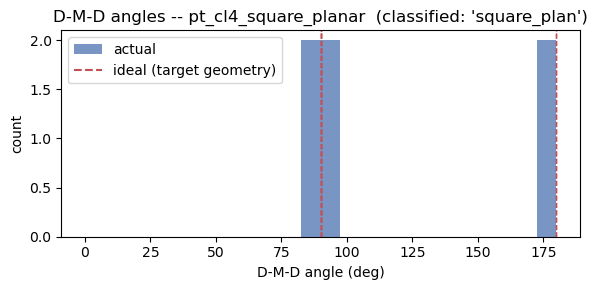

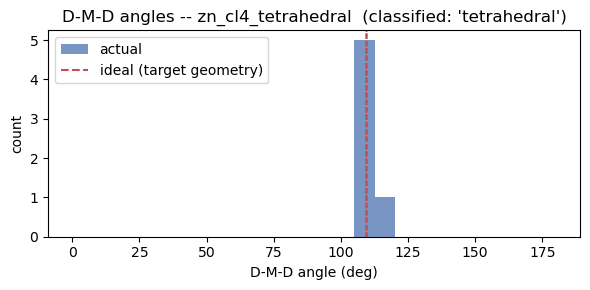

In [10]:
from jacobik.ik.targets import IDEAL_GEOMETRIES


def plot_dmd_angles(result, case: dict):
    mol = result.best.complex
    donor_idxs, angles, pairs = dmd_angles_deg(mol)

    ideal = IDEAL_GEOMETRIES.get(case["geometry"])
    ideal_angles = None
    if ideal is not None:
        dots = np.clip(ideal @ ideal.T, -1.0, 1.0)
        ideal_angles = np.degrees(np.arccos(dots))
        iu = np.triu_indices_from(ideal_angles, k=1)
        ideal_angles = np.sort(ideal_angles[iu])[::-1]

    fig, ax = plt.subplots(figsize=(6, 3))
    ax.hist(angles, bins=24, range=(0, 180), color="#4c72b0", alpha=0.75, label="actual")
    if ideal_angles is not None:
        for a in ideal_angles:
            ax.axvline(a, color="#c44e52", linestyle="--", linewidth=1)
        ax.plot([], [], color="#c44e52", linestyle="--", label="ideal (target geometry)")
    ax.set_xlabel("D-M-D angle (deg)"); ax.set_ylabel("count")
    ax.set_title(f"D-M-D angles -- {case['name']}  (classified: {classify_geometry(mol)!r})")
    ax.legend()
    plt.tight_layout()
    plt.show()


plot_dmd_angles(RESULTS["pt_cl4_square_planar"], CASES_BY_NAME["pt_cl4_square_planar"])
plot_dmd_angles(RESULTS["zn_cl4_tetrahedral"], CASES_BY_NAME["zn_cl4_tetrahedral"])


## 8. 3D structure

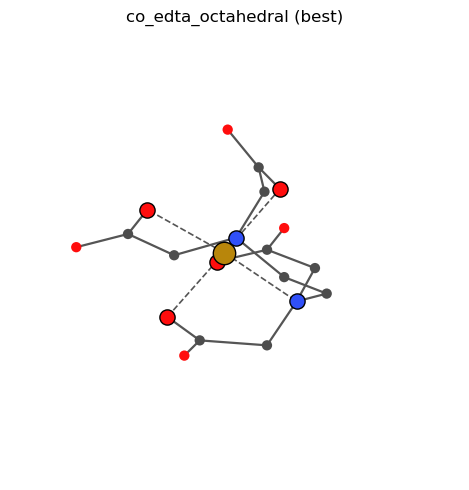

In [11]:
_ELEMENT_COLORS = {
    "H": "#dddddd", "C": "#4d4d4d", "N": "#3050f8", "O": "#ff0d0d",
    "P": "#ff8000", "S": "#ffff30", "Cl": "#1ff01f", "F": "#90e050",
}
_METAL_COLOR = "#b8860b"


def plot_structure_3d(mol, title="", show_hydrogen=False, elev=20, azim=35):
    fig = plt.figure(figsize=(5, 5))
    ax = fig.add_subplot(111, projection="3d")

    donor_set = set(mol.donor_labels.keys())
    for a in mol.atoms:
        if a.symbol == "H" and not show_hydrogen:
            continue
        color = _METAL_COLOR if a.idx == mol.metal_idx else _ELEMENT_COLORS.get(a.symbol, "#999999")
        size = 260 if a.idx == mol.metal_idx else (120 if a.idx in donor_set else 55)
        edge = "black" if a.idx in donor_set or a.idx == mol.metal_idx else "none"
        ax.scatter(*a.position, color=color, s=size, edgecolors=edge, linewidths=1.0, depthshade=True)

    atom_map = {a.idx: a for a in mol.atoms}
    for b in mol.bonds:
        ai, aj = atom_map.get(b.i), atom_map.get(b.j)
        if ai is None or aj is None:
            continue
        if not show_hydrogen and (ai.symbol == "H" or aj.symbol == "H"):
            continue
        style = "--" if (b.i == mol.metal_idx or b.j == mol.metal_idx) else "-"
        lw = 1.2 if style == "--" else 1.6
        ax.plot(*zip(ai.position, aj.position), style, color="#555555", linewidth=lw)

    ax.set_title(title)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=elev, azim=azim)
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()


plot_structure_3d(RESULTS["co_edta_octahedral"].best.complex, "co_edta_octahedral (best)")


In [20]:
from jacobik import Visualizer
vis = Visualizer(RESULTS["pt_cl4_square_planar"], show_hydrogen=False)
vis.view_ensemble_structs()

If `jacobik.vis.Visualizer` and its `ipywidgets`/`matplotlib` stack are
available in your kernel, it gives a richer interactive view (ensemble
overlay, ranking, heatmap) &mdash; try it for any case:

```python
from jacobik import Visualizer
vis = Visualizer(RESULTS["co_edta_octahedral"], show_hydrogen=False)
vis.view_ensemble_structs()
```

The `plot_structure_3d` above is the dependency-free fallback used
throughout this notebook so the dashboard always renders regardless of
what's installed in a given kernel.


## 9. Ensemble diversity

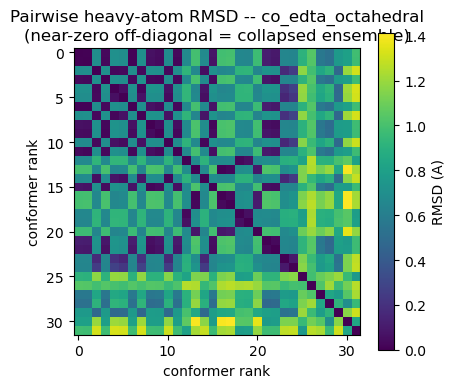

In [13]:
def plot_rmsd_heatmap(result, case_name=""):
    M = pairwise_rmsd_matrix(result.conformers)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    im = ax.imshow(M, cmap="viridis")
    ax.set_title(f"Pairwise heavy-atom RMSD -- {case_name}\n(near-zero off-diagonal = collapsed ensemble)")
    ax.set_xlabel("conformer rank"); ax.set_ylabel("conformer rank")
    fig.colorbar(im, ax=ax, label="RMSD (A)")
    plt.tight_layout()
    plt.show()
    return M


_ = plot_rmsd_heatmap(RESULTS["co_edta_octahedral"], "co_edta_octahedral")


## 10. Stats introspection &mdash; which fallback level fired?

`StatsLookup.dist_trace(quantity, key)` shows exactly which candidate key a
lookup resolved to. Use this whenever a case's geometry looks
statistically underdetermined, or to directly confirm the spin/multiplicity
fix: a diamagnetic Co(III) Q1 query should now resolve at **level 0** (the
exact key), not fall through to a coarse geometry-blind fallback.


In [14]:
def inspect_q1_for_donor(mol, donor_idx: int, coord_geom: str):
    from jacobik.ik.scorer import _trans_partners  # reuse the exact key logic Scorer uses

    label = mol.donor_labels[donor_idx]
    trans_map = _trans_partners(mol)
    site_i = next(i for i, s in enumerate(mol.coord_sites) if donor_idx in s.donor_indices)
    key = (mol.metal_symbol, mol.spin_state, mol.charge, label.subclass, coord_geom, trans_map.get(site_i, "none"))
    fd, resolved_key, candidates = STATS.dist_trace("Q1", key)
    level = candidates.index(resolved_key) if resolved_key in candidates else None
    print(f"query key      : {key}")
    print(f"resolved level : {level} / {len(candidates)-1}  {'(EXACT MATCH)' if level == 0 else '(fell back)'}")
    print(f"resolved key   : {resolved_key}")
    print(f"fitted         : n={fd.n}  type={fd.type}  means={fd.means}")
    return level


mol_co = RESULTS["co_nh3_6_octahedral"].best.complex
some_donor = next(iter(mol_co.donor_labels))
print("--- co_nh3_6_octahedral (diamagnetic, spin=1): should resolve at level 0 ---")
inspect_q1_for_donor(mol_co, some_donor, "octahedral")

print()
print("--- fe_h2o_6_highspin (spin=5): tmQM has essentially no open-shell data, ")
print("    expect a deep fallback -- this is a genuine data-coverage gap, not a bug ---")
mol_fe = RESULTS["fe_h2o_6_highspin"].best.complex
some_donor_fe = next(iter(mol_fe.donor_labels))
inspect_q1_for_donor(mol_fe, some_donor_fe, "octahedral")


--- co_nh3_6_octahedral (diamagnetic, spin=1): should resolve at level 0 ---
query key      : ('Co', 1, 3, 'N_amine', 'octahedral', 'N_amine')
resolved level : 6 / 10  (fell back)
resolved key   : ('Co', 'N_donor')
fitted         : n=3314  type=gmm  means=[0.14027402209449744, 1.8997662877594268, 1.940081245363194, 2.8687007730589795]

--- fe_h2o_6_highspin (spin=5): tmQM has essentially no open-shell data, 
    expect a deep fallback -- this is a genuine data-coverage gap, not a bug ---
query key      : ('Fe', 5, 2, 'O_water', 'octahedral', 'O_water')
resolved level : 6 / 10  (fell back)
resolved key   : ('Fe', 'O_donor')
fitted         : n=2032  type=gmm  means=[1.9230011867717465, 1.9852740950200451, 2.2236043828902505, 2.893808038155393]


6

## 11. Q2 aggregation A/B test (EXPERIMENTAL)

`Scorer` now has an opt-in `q2_aggregation="power_mean"` mode (default
remains `"mean"`, unchanged behaviour) that targets the documented Q2
mean-dilution issue -- see `ik/scorer.py`'s `Scorer.__init__` docstring for
the reasoning. **This has not been validated against a full benchmark
suite** -- this cell is exactly how to check that before trusting it on
anything beyond PtCl4. Also included: a zero-code-change baseline
(`quantity_weights={"Q2": ...}`) to help tell whether this is a
weighting problem or a structural aggregation problem.

**NOTE (post-consolidation refactor):** the `anchor_floor_frac` baseline
mentioned above was removed along with the OLD fixed-target anchor path
(see section 12) and is no longer part of this comparison.


[pt_cl4_square_planar] solved in 7.0s -- 16/16 converged -- best score=1.9888 -- donor subclasses=['Hal_Cl']


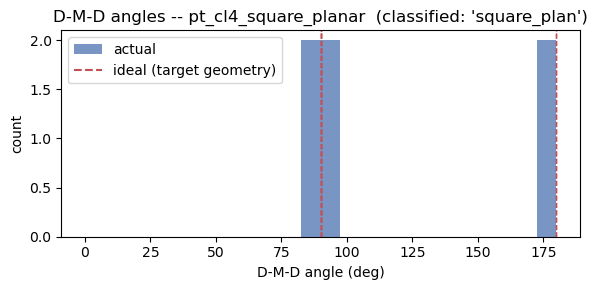

[pt_cl4_square_planar] solved in 7.2s -- 16/16 converged -- best score=0.4118 -- donor subclasses=['Hal_Cl']


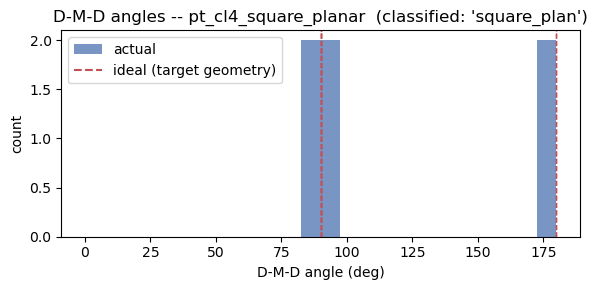

[pt_cl4_square_planar] solved in 6.8s -- 16/16 converged -- best score=0.3920 -- donor subclasses=['Hal_Cl']


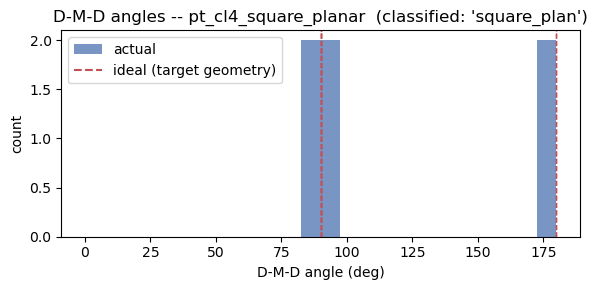

[pt_cl4_square_planar] solved in 6.8s -- 16/16 converged -- best score=3.5982 -- donor subclasses=['Hal_Cl']


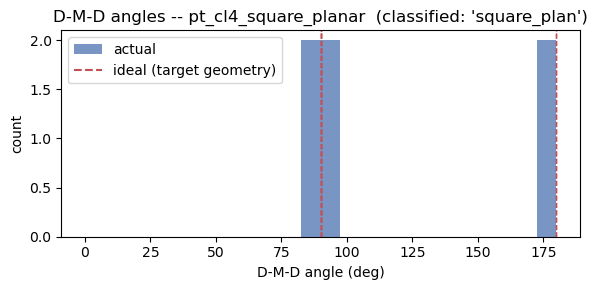

[pt_cl4_square_planar] solved in 6.7s -- 16/16 converged -- best score=1.9888 -- donor subclasses=['Hal_Cl']


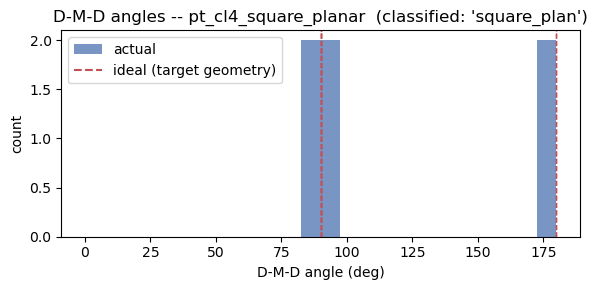

,shape_pass,classified_as,best_score,n_converged
variant,,,,
mean (current default),True,square_plan,1.988797,16
power_mean p=3,True,square_plan,0.411771,16
power_mean p=5,True,square_plan,0.391960,16
"mean, Q2 weight x5",True,square_plan,3.598234,16
"mean, anchor_floor_frac=0.05",True,square_plan,1.988797,16


In [15]:
_ab_case = CASES_BY_NAME["pt_cl4_square_planar"]

_ab_variants = {
    "mean (current default)": dict(),
    "power_mean p=3": dict(q2_aggregation="power_mean", q2_power_p=3.0),
    "power_mean p=5": dict(q2_aggregation="power_mean", q2_power_p=5.0),
    "mean, Q2 weight x5": dict(quantity_weights={"Q2": 5.0}),
}

_ab_rows = []
for _label, _kwargs in _ab_variants.items():
    _result, _elapsed = run_case(_ab_case, **_kwargs)
    _checks = run_all_checks(_result, _ab_case)
    _ab_rows.append({
        "variant": _label,
        "shape_pass": _checks["shape"]["pass"],
        "classified_as": _checks["shape"]["actual"],
        "best_score": _result.best.score,
        "n_converged": len(_result.converged),
    })
    plot_dmd_angles(_result, _ab_case)

pd.DataFrame(_ab_rows).set_index("variant")


## 12. Shape-ALM A/B test (2.6.0)

**NOTE (post-consolidation refactor):** the OLD fixed-absolute-target
anchor path (`use_shape_alm=False`) has been removed from `ik_solver.py`/
`engine.py` -- the Augmented-Lagrangian shape constraint described below
is now the only mechanism, so the OLD-vs-NEW comparison this section
originally ran can't be repeated. The remaining rows below (which tune
the surviving knobs: `shape_rho`, `sym_angle_weight`, `q3_mode_commit`)
still apply and are what the cell actually runs now.

Originally: tests the Augmented-Lagrangian shape constraint added in
`engine.py` 2.6.0 / `ik_solver.py` 2.3.0 (via a per-step-recomputed
optimal rotation + a symmetry-tying restraint on topologically-
equivalent donors), which replaced the old fixed-absolute-target anchor.

Runs both reported-broken cases -- PtCl4 (shape collapse) and EDTA
(bond-length spread between its two chemically-equivalent amine N
donors) -- across the tunables that survived the refactor.

See the changelog entries in `engine.py` (2.6.0) and
`ik/ik_solver.py` (`JointIKSolver` 2.3.0) for the full rationale.
`shape_rho`/`shape_tol`/`sym_weight` are starting defaults, not
empirically fit -- if shapes still fail here, that's the first thing
worth sweeping.

[pt_cl4_square_planar] solved in 6.2s -- 16/16 converged -- best score=2.2158 -- donor subclasses=['Hal_Cl']
[pt_cl4_square_planar] solved in 6.7s -- 16/16 converged -- best score=1.9888 -- donor subclasses=['Hal_Cl']
[pt_cl4_square_planar] solved in 6.9s -- 16/16 converged -- best score=1.9888 -- donor subclasses=['Hal_Cl']
[pt_cl4_square_planar] solved in 7.0s -- 16/16 converged -- best score=1.9888 -- donor subclasses=['Hal_Cl']
[pt_cl4_square_planar] solved in 6.8s -- 16/16 converged -- best score=1.9888 -- donor subclasses=['Hal_Cl']
[pt_cl4_square_planar] solved in 6.8s -- 16/16 converged -- best score=1.9888 -- donor subclasses=['Hal_Cl']


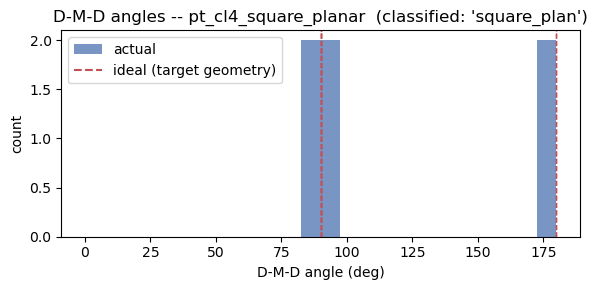

[co_edta_octahedral] solved in 24.6s -- 16/32 converged -- best score=-3.8884 -- donor subclasses=['N_amine', 'O_carboxylate']
[co_edta_octahedral] solved in 28.2s -- 10/32 converged -- best score=-5.2741 -- donor subclasses=['N_amine', 'O_carboxylate']
[co_edta_octahedral] solved in 26.7s -- 10/32 converged -- best score=-6.2350 -- donor subclasses=['N_amine', 'O_carboxylate']
[co_edta_octahedral] solved in 27.5s -- 10/32 converged -- best score=-5.2738 -- donor subclasses=['N_amine', 'O_carboxylate']
[co_edta_octahedral] solved in 27.3s -- 10/32 converged -- best score=-5.2749 -- donor subclasses=['N_amine', 'O_carboxylate']
[co_edta_octahedral] solved in 27.8s -- 16/32 converged -- best score=-4.1890 -- donor subclasses=['N_amine', 'O_carboxylate']


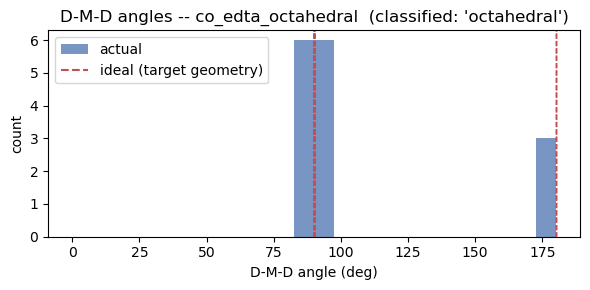

shape_pass  \
case                 variant                                                          
pt_cl4_square_planar OLD anchor (use_shape_alm=False)                         False   
                     NEW shape-ALM (default)                                   True   
                     NEW shape-ALM, shape_rho=20                               True   
                     NEW shape-ALM, sym_angle_weight=0.0 (angle tie ...        True   
                     NEW shape-ALM, sym_angle_weight=3.0                       True   
                     NEW shape-ALM, q3_mode_commit=False (mode-commi...        True   
co_edta_octahedral   OLD anchor (use_shape_alm=False)                          True   
                     NEW shape-ALM (default)                                   True   
                     NEW shape-ALM, shape_rho=20                               True   
                     NEW shape-ALM, sym_angle_weight=0.0 (angle tie ...        True   
                     NEW shape-ALM, sym_angle_weight=3.0                       True   
                     NEW shape-ALM, q3_mode_commit=False (mode-commi...        True   

                                                                        classified_as  \
case                 variant                                                            
pt_cl4_square_planar OLD anchor (use_shape_alm=False)                         see_saw   
                     NEW shape-ALM (default)                              square_plan   
                     NEW shape-ALM, shape_rho=20                          square_plan   
                     NEW shape-ALM, sym_angle_weight=0.0 (angle tie ...   square_plan   
                     NEW shape-ALM, sym_angle_weight=3.0                  square_plan   
                     NEW shape-ALM, q3_mode_commit=False (mode-commi...   square_plan   
co_edta_octahedral   OLD anchor (use_shape_alm=False)                      octahedral   
                     NEW shape-ALM (default)                               octahedral   
                     NEW shape-ALM, shape_rho=20                           octahedral   
                     NEW shape-ALM, sym_angle_weight=0.0 (angle tie ...    octahedral   
                     NEW shape-ALM, sym_angle_weight=3.0                   octahedral   
                     NEW shape-ALM, q3_mode_commit=False (mode-commi...    octahedral   

                                                                         bond_spread_A  \
case                 variant                                                             
pt_cl4_square_planar OLD anchor (use_shape_alm=False)                         0.027358   
                     NEW shape-ALM (default)                                  0.026398   
                     NEW shape-ALM, shape_rho=20                              0.028288   
                     NEW shape-ALM, sym_angle_weight=0.0 (angle tie ...       0.026398   
                     NEW shape-ALM, sym_angle_weight=3.0                      0.026398   
                     NEW shape-ALM, q3_mode_commit=False (mode-commi...       0.026398   
co_edta_octahedral   OLD anchor (use_shape_alm=False)                         0.595613   
                     NEW shape-ALM (default)                                  0.312426   
                     NEW shape-ALM, shape_rho=20                              0.340753   
                     NEW shape-ALM, sym_angle_weight=0.0 (angle tie ...       0.310315   
                     NEW shape-ALM, sym_angle_weight=3.0                      0.312200   
                     NEW shape-ALM, q3_mode_commit=False (mode-commi...       0.172107   

                                                                         dangling_arm_pass  \
case                 variant                                                                 
pt_cl4_square_planar OLD anchor (use_shape_alm=False)                                 True   
                     NEW shape-ALM (default)                    

In [16]:
_shape_ab_cases = [
    CASES_BY_NAME["pt_cl4_square_planar"],
    CASES_BY_NAME["co_edta_octahedral"],
]

# NOTE (post-consolidation refactor): the OLD fixed-target anchor path
# (use_shape_alm=False) was removed from ik_solver.py/engine.py -- the
# shape-ALM mechanism this section validated is now the ONLY path, so the
# "OLD anchor" row from the original A/B can no longer be run. The
# remaining rows still isolate the tunables that survived the refactor.
_shape_ab_variants = {
    "shape-ALM (default)": dict(),
    "shape-ALM, shape_rho=20": dict(ik_config=IKSolverConfig(shape_rho=20.0)),
    # 2.4.0/2.7.0: Q3 approach-angle symmetry tie (see ik_solver.py's
    # changelog history) -- added to address the EDTA "uneven N anchoring /
    # carboxylate spread" regression reported after the Q2/Q3 GMM-cos
    # refit. sym_angle_weight=0.0 reproduces angle-tie-off behaviour, a
    # clean A/B against the "shape-ALM (default)" row above, which has
    # sym_angle_weight=1.0 baked in.
    "shape-ALM, sym_angle_weight=0.0 (angle tie OFF)": dict(
        ik_config=IKSolverConfig(sym_angle_weight=0.0)
    ),
    "shape-ALM, sym_angle_weight=3.0": dict(ik_config=IKSolverConfig(sym_angle_weight=3.0)),
    # 2.5.0/2.8.0: mode-committed Q3 initialization. Root cause found AFTER
    # the sym_angle_weight rows above shipped: sym_angle_weight ties
    # symmetric donors toward their MEAN Q3 angle, but O_carboxylate's
    # fitted Q3 GMM (Co/octahedral) is genuinely 5-modal (~87-130 deg,
    # confirmed against the live constraints.json) -- for EDTA's 4
    # carboxylate O (one RDKit-symmetric group), the mean of two
    # well-separated modes lands in the low-density valley BETWEEN them,
    # which explains why sym_angle_weight=0/1/3 all looked similarly bad in
    # the first re-run (this row's default sibling above, "shape-ALM
    # (default)", now has q3_mode_commit=True baked in, since it defaults
    # True in engine.py -- this row isolates the effect by turning it off).
    "shape-ALM, q3_mode_commit=False (mode-commit OFF)": dict(q3_mode_commit=False),
}

_shape_ab_rows = []
for _case in _shape_ab_cases:
    for _label, _kwargs in _shape_ab_variants.items():
        _result, _elapsed = run_case(_case, **_kwargs)
        _checks = run_all_checks(_result, _case)
        _mol = _result.best.complex
        _donor_idxs, _dists = donor_metal_distances(_mol)
        _shape_ab_rows.append({
        "case": _case["name"],
        "variant": _label,
        "shape_pass": _checks["shape"]["pass"],
        "classified_as": _checks["shape"]["actual"],
        "bond_spread_A": _checks["bond_spread"]["spread_A"],
        "dangling_arm_pass": _checks["dangling_arm"]["pass"],
        "best_score": _result.best.score,
        "n_converged": len(_result.converged),
        })
    plot_dmd_angles(_result, _case)

_shape_ab_df = pd.DataFrame(_shape_ab_rows).set_index(["case", "variant"])
_shape_ab_df

## 13. Debugging playground

Pick any registered case, rerun with `debug=True` for full solver
diagnostics (printed inline by the engine), and get every plot above in one
place. Edit `CASE_NAME` and any `overrides` and rerun this cell.


In [17]:
CASE_NAME = "co_edta_octahedral"
case = CASES_BY_NAME[CASE_NAME]

result, elapsed = run_case(case, debug=True)  # add overrides as kwargs, e.g. seed=7, beam_width=32
checks = run_all_checks(result, case)

print("\n=== checks ===")
for k, v in checks.items():
    print(f"  {k:14s} pass={v['pass']!s:5}  {v.get('message', '')}")

plot_score_breakdown(result, CASE_NAME)
plot_convergence(result, CASE_NAME)
plot_dmd_angles(result, case)
plot_structure_3d(result.best.complex, f"{CASE_NAME} (best)")
_ = plot_rmsd_heatmap(result, CASE_NAME)



[DEBUG] ── Step 2: Complex shell built ──────────────────────
  metal=Co  geometry=octahedral  charge=-1  spin=1
  Total atoms : 33
  Coord sites : 6
    site[0] kappa  donor_indices=[2]
    site[1] kappa  donor_indices=[6]
    site[2] kappa  donor_indices=[9]
    site[3] kappa  donor_indices=[13]
    site[4] kappa  donor_indices=[17]
    site[5] kappa  donor_indices=[21]

[DEBUG]   Symmetric donor groups (2.3.0): [[0, 3, 4, 5], [1, 2]]

[DEBUG] ── Donor 0 (lig=0 grp=0) ──────────────
  subclass='O_carboxylate'  family='O_donor'  trans_partner='N_amine'
  Q1 key   : ('Co', 1, -1, 'O_carboxylate', 'octahedral', 'N_amine')
  sampled M-D lengths: mean=1.8881 min=1.8496 max=1.9218 Å (M=8)
  site_vec : [0. 0. 1.]
  targets[0]: [0.         0.         1.88022658]  (norm=1.8802 Å)

[DEBUG] ── Donor 1 (lig=0 grp=1) ──────────────
  subclass='N_amine'  family='N_donor'  trans_partner='O_carboxylate'
  Q1 key   : ('Co', 1, -1, 'N_amine', 'octahedral', 'O_carboxylate')
  sampled M-D lengths: mean

KeyboardInterrupt: 

## Known open issues (context for anything that fails above)

- **2.6.0 update**: the old fixed-absolute-target anchor (which went
  stale as soon as the ligand's pose or torsions moved from its initial
  Kabsch fit) is now replaced by default with an Augmented-Lagrangian
  shape constraint recomputed every step, plus a symmetry-tying
  restraint on topologically-equivalent donors. Run section 12 above
  first on any new failure -- if `use_shape_alm=False` (old) also
  fails the same way, the bug predates this change and isn't the shape/
  anchor mechanism; if only the new path fails, `shape_rho`/`shape_tol`/
  `sym_weight` are the first knobs to sweep (they're starting defaults,
  not empirically fit).
- Q2's arithmetic-mean pairwise-angle aggregation still dilutes a single
  badly-wrong D-M-D pair across all pairs (documented in scorer.py's own
  changelog). The `q2_aggregation="power_mean"` experimental alternative
  (section 11) is now largely superseded by the shape-ALM term for
  *overall polyhedron shape* -- Q2 itself still governs the finer-grained
  angular statistical preference within a shape, so the dilution issue
  there is not fully closed by 2.6.0.
- **2.7.0 update**: Q2 (D-M-D angle) and Q3 (donor approach angle) are
  refit as GMM-on-cos(angle) instead of VMM (both are bounded [0,180]
  deg via arccos and never wrap to 360, so they were never circular --
  see stats/fitter.py's fit_gmm_cosangle() docstring and ik/scorer.py's
  2.7.0 changelog entry for the full rationale). Confirmed post-refit:
  e.g. Q3 for C_carbonyl/Mo/other now has a dominant component at
  ~175 deg with cos-space var ~1.8e-5 (sigma ~1.5 deg) and weight 0.72
  -- much sharper than the old VMM fit allowed near a hard boundary --
  which should directly help the "ligands not pointing straight"
  symptom for linear/near-linear approach donors like CO. If TBP-vs-
  square-pyramidal ranking or ligand-orientation issues persist after
  this, the remaining known lever is folding the shape-deviation
  signal (`solve_trace["anchor_loss"]` under `use_shape_alm=True`,
  section 12) into final conformer ranking -- currently ranking uses
  only the Q1-Q6 statistical score, excluding shape fidelity entirely.
- **2.4.0/2.7.0 update**: added a second symmetry-tying restraint
  (`sym_angle_weight`, default 1.0) that ties Q3 approach angle
  between topologically-equivalent donors, alongside the existing
  M-D distance tie. Root cause: EVERY Q3 entry in the live
  constraints.json turned out to have been running through a broken
  score-time fallback (kappa clamped to 10) for its whole history --
  independent of, and prior to, the periodicity issue the Q2/Q3
  refit above fixed. Once that refit gave Q3 real teeth for the
  first time, nothing stopped two chemically-identical donors (e.g.
  EDTA's two amine N) from landing near different Q3 modes -- a
  plausible mechanism for the uneven-N-anchoring/carboxylate-spread
  regression reported after that refit. Run section 12's new
  `sym_angle_weight=0.0` vs default rows on EDTA to confirm this
  actually helps before trusting it -- NOT YET VALIDATED against a
  live solve (implemented from static constraints.json inspection
  only, since Claude cannot run torch here). `sym_angle_weight=1.0`
  is a starting default, not empirically fit.
- **2.5.0/2.8.0 update -- the actual EDTA fix (supersedes the
  2.4.0/2.7.0 sym_angle_weight note below, which the user's own
  re-run showed had negligible effect on bond_spread_A)**: traced the
  regression to a live query against constraints.json --
  Q3(O_carboxylate, Co, octahedral) is a REAL 5-component GMM (cos-
  space modes -0.638/-0.486/-0.439/-0.028/+0.045, i.e. ~87-130 deg),
  reflecting genuinely different carboxylate binding modes pooled
  from the CSD, not a fitting artifact. EDTA's 4 carboxylate O are
  one RDKit-symmetric group, so each independently settles near
  whichever mode it's nearest to, and sym_angle_weight's mean-tie can
  land the group in the low-density valley BETWEEN two well-
  separated modes -- worse than either mode alone, and consistent
  with n_converged collapsing (29 -> 1-2/32) and being insensitive to
  sym_angle_weight's value (0/1/3 all similarly bad): 'converged'
  means score-plateaued, and a tug-of-war between modes can oscillate
  rather than plateau. Fix: q3_mode_commit (default True) hard-
  selects ONE GMM component per symmetric group per trial from the
  INITIAL pose, instead of letting members drift and then averaging.
  See ik_solver.py's 2.5.0 changelog for the full mechanism. NOT YET
  VALIDATED against a live solve at the time of writing (implemented
  from static constraints.json inspection + code-path tracing only,
  since Claude cannot run torch here) -- run this section's new
  `q3_mode_commit=False` row against its default-True sibling on
  EDTA to confirm before trusting it.
- **2.9.0 fix (separate, Q1-only)**: query-time Q1 keys used the
  complex's raw, unclamped charge, but the live constraints.json only
  contains charge in {-1, 0, 1} for every metal. Any |charge|>1 case
  (e.g. [Co(NH3)6]3+, charge=+3) could never match any Q1 candidate
  that still conditions on charge -- confirmed via a live trace:
  co_nh3_6_octahedral resolved at fallback level 6/10 (Co, N_donor),
  losing donor-subclass AND geometry specificity together, despite
  being an extremely well-represented CSD case. Now clamped to the
  nearest available bucket (scorer.py's _clamp_q1_charge()); verified
  against the live DB post-fix: co_nh3_6_octahedral now resolves at
  level 0/10 (exact match, n=958), pt_cl4 at level 0/9 (was 5/9),
  zn_cl4 at level 2/9 (was 5/9). Unrelated to the EDTA/Q3 fix above;
  mentioned here only because it was found via the same diagnostic
  trace the user posted.
- **Audit finding (2.7.0, not yet addressed)**: Q2's key construction
  (`_graph_dist_class` in stats/key_builder.py) pools ALL cross-ligand
  donor pairs under one `"different_ligand"` key regardless of their
  actual cis/trans relationship -- unlike Q1, which has a proper
  `trans_partner`-aware key (`_trans_partners()`, based on measured
  angle > 140 deg). Confirmed identical at both fit-time (key_builder.
  py) and score-time (ik/scorer.py's Q2 construction block reuses the
  same `_graph_dist_class` call). Consequence: for any homoleptic
  monodentate complex (PtCl4, Fe(CO)5, Co(NH3)6, ...), every pairwise
  D-M-D angle shares ONE fitted distribution -- a pooled mixture of
  cis-like and trans-like observations -- so Q2 can only shape the
  aggregate angle histogram, not enforce which specific pairs should
  be cis vs trans. This is a real, significant limitation (part of
  why the shape-ALM/CShM term in 2.3.0 was needed in the first place)
  but a separate, larger fix than the model-family refit above --
  would need Hungarian-assignment info threaded into Scorer.__init__
  for score-time-aware keys, plus new fit-time key logic. Deferred.
- **NOTE (post-consolidation refactor):** `anchor_floor_frac` and the OLD
  (`use_shape_alm=False`) fallback path it belonged to have both been
  removed entirely -- the shape-ALM dual multiplier is now the only
  mechanism, and no manual floor is needed or available on it.
- Haptic (multi-atom) donor groups are skipped by the new symmetry-tying
  restraint's equivalence detection -- untested for that case.- **2.6.0 (`ik_solver.py`) / 2.9.0 (`engine.py`) fix, not yet run against a live solve**: `mu_shape` (the shape-ALM dual variable) was found via `solve_trace` inspection to grow WITHOUT BOUND for the full solve whenever the shape constraint is effectively infeasible (EDTA's `shape_dev` plateaus at ~0.89, ~45x `shape_tol`, within 50-75 steps and never moves again, while `mu_shape` keeps climbing linearly for the full T, reaching 1500-2000+). This dwarfs the fixed-weight `sym_weight`/`sym_angle_weight` restraints by 3000-3600x by step 199 (vs 17-84x at step 0) -- the actual, confirmed mechanism behind EDTA's two amine N ending up at very different M-D distances despite the restraint meant to prevent that, and it retroactively explains why the 2.4.0/2.7.0 `sym_angle_weight` sweep above found no effect: against a term already in the thousands, that weight range is noise. `mu_shape_freeze_on_stall` (default True, new) freezes `mu_shape` once `violation` stalls (safeguarded-ALM, cf. Birgin & Martinez); `sym_weight_tracks_mu` (default True, new) scales the symmetry-tying weights alongside `mu_shape` so they don't get drowned out. Neither touches `shape_tol`, the Hungarian donor-vertex assignment, or Q3 handling. Run section 14 above (PtCl4 / Fe(CO)5 / EDTA, both fixes on vs off) before trusting this -- it needs a live solve to confirm PtCl4 and Fe(CO)5 stay intact and EDTA's `symmetric_pair_spread_A` actually shrinks.


- **2.10.0/2.11.0 update -- the actual root cause of the amine asymmetry.** Sections 14-15's fixes (`mu_shape`, `sym_weight`/`mu_sym`, `sym_use_own_alm`) are all reweightings of the SAME loss terms, and per section 14's live results, the best of them only cut EDTA's `symmetric_pair_spread_A` by ~12% with real side effects elsewhere (PtCl4 `bond_spread_A` regressed 0.028->0.103 A). Root cause, confirmed directly against `fk.py`'s actual joint construction and `decompose.py`'s own documented KNOWN LIMIT (`_select_root_body` 1.2.1): a branch-point kappa donor (a tertiary amine N, exactly EDTA's case) has NO joint, under the pre-2.4.0 torsion set, that can change its own local pyramidal/approach geometry independently of its sibling branches -- the one joint that reaches it from root sweeps all its branches together as a rigid unit, preserving their mutual angles exactly. No amount of reweighting can fix a term with no independent parameter to act on, which is exactly why `sym_angle_weight`'s 0/1/3 sweep (2.4.0/2.7.0, above) found no effect. `enable_bend_dof=True` (`fk.py` 2.4.0, new default) gives such donors a genuine new joint per outgoing branch; verified standalone (synthetic tetrahedral donor, pure numpy) to preserve bond length/angle exactly while giving real independent reach over the donor's own approach geometry. Not yet validated against a live solve -- run section 16 above (`enable_bend_dof` True vs False, with the new `donor_q3_angles_deg` per-donor diagnostic) before trusting this.

## 14. mu_shape safeguard A/B (`ik_solver.py` 2.6.0 / `engine.py` 2.9.0)

**NOTE (post-consolidation refactor):** `sym_weight_tracks_mu` (and the
fixed-ratio mechanism it toggled) was removed -- every symmetry-tying
restraint now always uses its own independent dual-ascent variable
instead (see section 15's note). Only the `mu_shape_freeze_on_stall`
axis below still exists to run; references to `sym_weight_tracks_mu` in
the historical narrative below describe why it was tried and dropped.

Section 12's shape-ALM A/B test found the mechanism works (EDTA's shape classification went from misclassified to correct), but did not explain -- and section 12's `sym_angle_weight`/`q3_mode_commit` rows did not fix -- EDTA's remaining symptom: bond-length spread blew up and `n_converged` collapsed. A `solve_trace` diagnostic session traced this to `mu_shape` (the shape-ALM dual variable) growing WITHOUT BOUND for the full solve whenever the shape constraint is effectively infeasible -- EDTA's `shape_dev` plateaus around 0.89 (~45x `shape_tol`) within 50-75 steps and never moves again, while `mu_shape` climbs linearly the whole time, reaching 1500-2000+ by step 199. That doesn't just fail on its own terms: it comes to dominate the combined loss so completely that the FIXED-weight `sym_weight`/`sym_angle_weight` symmetry-tying restraints become numerically irrelevant (measured ratio of shape-penalty : sym-tie-penalty: 17-84x at step 0, 3000-3600x by step 199) -- which is exactly why the two topologically-equivalent amine N in EDTA never actually converge to the same M-D distance despite an explicit restraint meant to enforce that, and why section 12's `sym_angle_weight` sweep found no effect (against a competing term already in the thousands, 0 vs 1 vs 3 is noise).

`mu_shape_freeze_on_stall` (default True) is a safeguarded-ALM fix (cf. Birgin & Martinez) that stops escalating `mu_shape` once `violation` itself has stalled. `sym_weight_tracks_mu` (default True) scales `sym_weight`/`sym_angle_weight` alongside `mu_shape` so their relative influence doesn't decay. Both are new, both default on, and **neither has been run against a live solve yet** (implemented from `solve_trace` data + code-path tracing only, since Claude cannot run torch in the environment this was developed in) -- this section is that first test.

Runs PtCl4 (square-planar) and Fe(CO)5 (trigonal-bipyramidal) alongside EDTA specifically because the concern raised this session was that anything touching the shape term's strength could break those discrete-geometry cases even while fixing EDTA -- watch `shape_pass`/`classified_as`/`n_converged` for those two rows staying stable across all four variants below, and watch `symmetric_pair_spread_A` (the M-D distance gap between EDTA's two amine N specifically, isolated from the whole-shell `bond_spread_A`) shrink in the last row relative to the first.

In [ ]:
_mu_ab_cases = [
    CASES_BY_NAME["pt_cl4_square_planar"],
    CASES_BY_NAME["fe_co5_trig_bipyr"],
    CASES_BY_NAME["co_edta_octahedral"],
]

# NOTE (post-consolidation refactor): sym_weight_tracks_mu (and the
# fixed-ratio mechanism it toggled) was removed -- every symmetry tie now
# always uses its own independent dual-ascent variable (formerly gated by
# sym_use_own_alm, which is likewise gone -- see section 15's note below).
# Only the mu_shape_freeze_on_stall axis of this A/B still exists to run.
_mu_ab_variants = {
    "freeze OFF": dict(ik_config=IKSolverConfig(mu_shape_freeze_on_stall=False)),
    "freeze ON (default)": dict(),
}

_mu_ab_rows = []
for _case in _mu_ab_cases:
    for _label, _kwargs in _mu_ab_variants.items():
        _result, _elapsed = run_case(_case, **_kwargs)
        _checks = run_all_checks(_result, _case)
        _mol = _result.best.complex
        _donor_idxs, _dists = donor_metal_distances(_mol)

        # Isolate any donor SUBCLASS that appears exactly twice for this
        # case (e.g. EDTA's two amine N) and report the M-D distance gap
        # within just that pair -- the literal reported symptom ("one
        # amine close, one far") that bond_spread_A (spread across ALL
        # donors in the shell) can't isolate on its own. None/None for
        # cases with no such pair (PtCl4, Fe(CO)5 -- all donors share one
        # subclass there).
        _subclass_to_idxs: dict[str, list[int]] = {}
        for _di in _donor_idxs:
            _sc = _mol.donor_labels[_di].subclass
            _subclass_to_idxs.setdefault(_sc, []).append(_di)
        _pair_spread_A = None
        _pair_subclass = None
        for _sc, _idxs in _subclass_to_idxs.items():
            if len(_idxs) == 2:
                _d0 = _dists[_donor_idxs.index(_idxs[0])]
                _d1 = _dists[_donor_idxs.index(_idxs[1])]
                _pair_spread_A = float(abs(_d0 - _d1))
                _pair_subclass = _sc
                break  # EDTA has exactly one such pair (the two amine N)

        _mu_ab_rows.append({
            "case": _case["name"],
            "variant": _label,
            "shape_pass": _checks["shape"]["pass"],
            "classified_as": _checks["shape"]["actual"],
            "bond_spread_A": _checks["bond_spread"]["spread_A"],
            "symmetric_pair_subclass": _pair_subclass,
            "symmetric_pair_spread_A": _pair_spread_A,
            "dangling_arm_pass": _checks["dangling_arm"]["pass"],
            "best_score": _result.best.score,
            "n_converged": len(_result.converged),
        })
    plot_dmd_angles(_result, _case)

_mu_ab_df = pd.DataFrame(_mu_ab_rows).set_index(["case", "variant"])
_mu_ab_df

## 15. sym_use_own_alm validation (`ik_solver.py` 2.7.0 / `engine.py` 2.10.0)

**NOTE (post-consolidation refactor):** `sym_use_own_alm` and
`sym_weight_tracks_mu` were both removed as toggles -- the independent
`mu_sym`/`mu_sym_angle` dual-ascent mechanism this section validated
(and found to be the winner) is now permanently on, with no alternative
left to compare it against. The code cell below has been retired
accordingly; the narrative below is kept as the record of *why* the
alternatives were removed.

Section 14's `sym_weight_tracks_mu` fix turned out not to generalize: it
regressed PtCl4's `bond_spread_A` (0.028 -> 0.103 A) even though PtCl4 has
no symmetric-tie donors at all, and only cut EDTA's amine-asymmetry
(`symmetric_pair_spread_A`) by ~12%. The problem wasn't the *size* of
`sym_weight` -- it was the *mechanism*: pinning sym_weight's ratio to
`mu_shape` couples one constraint's weight to a different constraint's
escalation, and only prevents that ratio from decaying further, it doesn't
fix the ratio being wrong from step 0. A hand-tuned `sym_weight` constant
(or ratio) fit against these three test cases would have the same defect --
it would be fit to these cases' symptoms, not a mechanism, and wouldn't
generalize to a different ligand.

The generalizable version (2.7.0/2.10.0): `sym_penalty` and
`sym_angle_penalty` each get their **own** safeguarded-ALM dual variable
(`mu_sym`, `mu_sym_angle`) that escalates off their **own** violation,
exactly the way `mu_shape` already does for the shape constraint --
standard multi-constraint ALM, no ratio to another constraint and no
hand-picked magnitude. This is `sym_use_own_alm=True`, the new default.

This cell runs a 3-way A/B/C across the same three geometry classes as
section 14:

- **pre-2.6.0 fixed weight** (`sym_use_own_alm=False`,
  `sym_weight_tracks_mu=False`): the original baseline, before any of this
  session's fixes.
- **2.9.0 `sym_weight_tracks_mu`** (`sym_use_own_alm=False`,
  `sym_weight_tracks_mu=True`): section 14's "NEW default" -- kept here as
  the thing we're trying to beat, not as a candidate.
- **2.10.0 `sym_use_own_alm`** (the new default): independent mu_sym /
  mu_sym_angle dual ascent.

Looking for: does `sym_use_own_alm` (a) leave PtCl4/Fe(CO)5 at or near
their pre-2.6.0 baseline `bond_spread_A`/`shape_pass`/`n_converged`
(no regression on cases it shouldn't touch), and (b) cut EDTA's
`symmetric_pair_spread_A` by materially more than the ~12% the ratio-based
fix achieved, without a worse `dangling_arm_pass`/`n_converged` than
2.9.0's row -- with none of it depending on a constant tuned to these three
cases.

**Bugfix (before this was ever run):** the first draft of the code cell below called this notebook's own helpers with a made-up API (`donor_metal_distances(result, case)` instead of the real `donor_metal_distances(mol)`, `run_all_checks`'s actual key names `"shape"`/`"bond_spread"`/`"dangling_arm"` instead of invented ones, and `CASES_BY_NAME` entries treated as objects instead of the plain dicts they are) and would have raised immediately. Rewritten to match section 14's (cell 36) proven-working pattern exactly -- this version has not been run yet either, so treat the first run as the real syntax/API check, not just a logic check.

In [ ]:
# NOTE (post-consolidation refactor): sym_use_own_alm and sym_weight_tracks_mu
# were both removed from JointIKSolver/ComplexBuilder.solve(). Every
# symmetry-tying constraint (M-D distance tie and Q3 approach-angle tie)
# always gets its own independent safeguarded-ALM dual variable now
# (mu_sym, mu_sym_angle) -- i.e. permanently the "2.10.0 sym_use_own_alm=T"
# row from the original 3-way comparison below, which is what this section
# found to be the winning mechanism in the first place. There is no
# alternate mechanism left to A/B against, so this comparison can't be
# re-run as originally written; the result found here is *why* the
# alternatives were removed.
print(
    "Retired: sym_use_own_alm is no longer a toggle -- its mechanism "
    "(independent mu_sym / mu_sym_angle dual ascent) is now always on."
)


## 16. `enable_bend_dof` validation -- the actual amine-inversion fix (`fk.py` 2.4.0 / `beam.py` 2.1.0 / `engine.py` 2.11.0)

Sections 14-15 were all reweighting fixes (`mu_shape`, `sym_weight`/`mu_sym`,
`sym_use_own_alm`) on top of the SAME set of loss terms, and none of them
could fully close EDTA's amine-nitrogen asymmetry -- the best any of them
did was shrink `symmetric_pair_spread_A` by ~12%, with real side effects
elsewhere. The reason turned out to be architectural, not a weighting
problem: tracing through `fk.py`'s actual joint construction (and
`decompose.py`'s own documented KNOWN LIMIT, `_select_root_body` 1.2.1)
confirmed that a branch-point kappa donor -- exactly what EDTA's two
tertiary amine nitrogens are -- has NO joint, under the pre-2.4.0 torsion
set, that can change its own local pyramidal/approach geometry
independently of its sibling branches. The one existing joint that reaches
such a donor from root sweeps ALL of its branches together as a rigid
unit (preserving their mutual angles exactly); each branch's own joint only
reorients what's further downstream of THAT branch, never its own
direction from the donor. No amount of reweighting can fix a term that has
no independent parameter to act on -- which is exactly why `mu_shape`,
`sym_weight`/`mu_sym`, and even `sym_angle_weight` (0/1/3, "statistically
indistinguishable" per the original handoff) all came back inert on this
specific symptom.

`enable_bend_dof=True` (new default) gives each such donor genuine
independent control: one new joint per outgoing branch, rotating only that
branch's own subtree around the donor's incoming-bond axis. This was
verified standalone (synthetic tetrahedral donor, pure numpy, no torch
needed) to preserve bond length/angle exactly while giving real reach over
the donor's own approach geometry -- see `fk.py`'s 2.4.0 changelog for the
derivation and numbers. It has **not** been validated against a live solve
yet -- that's what this cell does.

The cell below adds a direct measurement the earlier sections didn't have:
`donor_q3_angles_deg`, a notebook-side reimplementation of `ik/geometry.py`'s
own Q3 definition (angle between M-D and D's own bond to the centroid of
its *other* heavy neighbours -- ~180 deg is a well-formed pyramidal
approach; a small angle means the metal is on the wrong side of the
donor's local geometry, i.e. the "inverted" failure mode reported directly
from an actual solved structure). For EDTA's two amine N, this reports each
one's own Q3 angle and the GAP between them -- the literal "one is close
and proper, the other is far/inverted" symptom, which `symmetric_pair_spread_A`
(a distance metric) can't see on its own. PtCl4/Fe(CO)5 are included purely
as a regression check (neither has a symmetric branch-point donor, so
`enable_bend_dof` should be a no-op for them).

Looking for: with `enable_bend_dof=True`, do EDTA's two amine Q3 angles
converge toward each other AND toward ~180 deg (both well-formed), while
PtCl4/Fe(CO)5's `shape_pass`/`bond_spread_A`/`n_converged` stay at their
baseline?

In [ ]:
def donor_q3_angles_deg(mol) -> dict[int, float]:
    """Angle (deg) between M-D and D's own bond to the centroid of its
    OTHER heavy neighbours -- reimplements ik/geometry.py's q3_approach_angles
    definition directly from mol's atoms/bonds (no torch needed here).
    ~180 deg = well-formed pyramidal approach (metal opposite the
    substituent bulk); a small angle = the metal is on the WRONG side of
    the donor's local geometry (the reported "inverted amine" symptom)."""
    G = build_heavy_ligand_graph(mol.atoms, mol.bonds, mol.metal_idx)
    metal_pos = np.asarray(mol.get_atom(mol.metal_idx).position, dtype=float)
    out: dict[int, float] = {}
    for d in sorted(mol.donor_labels.keys()):
        if not G.has_node(d):
            continue
        nbs = [n for n in G.neighbors(d) if n != mol.metal_idx]
        if not nbs:
            continue
        d_pos = np.asarray(mol.get_atom(d).position, dtype=float)
        sub_pos = np.array([np.asarray(mol.get_atom(n).position, dtype=float) for n in nbs])
        centroid = sub_pos.mean(axis=0)
        v_M = metal_pos - d_pos
        v_C = centroid - d_pos
        cos_a = float(np.dot(v_M, v_C) / (np.linalg.norm(v_M) * np.linalg.norm(v_C)))
        out[d] = math.degrees(math.acos(np.clip(cos_a, -1.0, 1.0)))
    return out


_bend_cases = [
    CASES_BY_NAME["pt_cl4_square_planar"],
    CASES_BY_NAME["fe_co5_trig_bipyr"],
    CASES_BY_NAME["co_edta_octahedral"],
]

_bend_variants = {
    "enable_bend_dof=False (pre-bend-DOF baseline)": dict(enable_bend_dof=False),
    "enable_bend_dof=True (default)": dict(enable_bend_dof=True),
}

_bend_rows = []
for _case in _bend_cases:
    for _label, _kwargs in _bend_variants.items():
        _result, _elapsed = run_case(_case, **_kwargs)
        _checks = run_all_checks(_result, _case)
        _mol = _result.best.complex
        _donor_idxs, _dists = donor_metal_distances(_mol)
        _q3 = donor_q3_angles_deg(_mol)

        _subclass_to_idxs: dict[str, list[int]] = {}
        for _di in _donor_idxs:
            _sc = _mol.donor_labels[_di].subclass
            _subclass_to_idxs.setdefault(_sc, []).append(_di)
        _pair_subclass = None
        _pair_q3_min = _pair_q3_max = _pair_q3_gap = float("nan")
        for _sc, _idxs in _subclass_to_idxs.items():
            if len(_idxs) == 2 and all(i in _q3 for i in _idxs):
                _pair_subclass = _sc
                _q3_vals = [_q3[i] for i in _idxs]
                _pair_q3_min, _pair_q3_max = min(_q3_vals), max(_q3_vals)
                _pair_q3_gap = _pair_q3_max - _pair_q3_min
                break

        _bend_rows.append({
            "case": _case["name"],
            "variant": _label,
            "shape_pass": _checks["shape"]["pass"],
            "bond_spread_A": _checks["bond_spread"]["spread_A"],
            "dangling_arm_pass": _checks["dangling_arm"]["pass"],
            "symmetric_pair_subclass": _pair_subclass,
            "pair_q3_min_deg": _pair_q3_min,
            "pair_q3_max_deg": _pair_q3_max,
            "pair_q3_gap_deg": _pair_q3_gap,
            "best_score": _result.best.score,
            "n_converged": len(_result.converged),
        })

_bend_df = pd.DataFrame(_bend_rows).set_index(["case", "variant"])
_bend_df